In [ ]:
# Regresie Univariata -> Metoda celor mai mici patrate

In [1]:
import csv
import os
import matplotlib.pyplot as plt
import numpy as np
from sklearn import linear_model

# functie cu parametru de file si feature
# plot pt distributia datelor & plot pt “verificarea” liniaritatii (daca legatura intre y si x e una liniara)
# impartire date pe train si test
# invatare model (cu tool generic si cu tool de least square)
# plot rezultate
# calcul metrici de performanta (eroarea)



In [2]:
# I
# Pas 1
# Load data and consider a single feature (Economy..GDP.per.capita) and the output to be estimated (happiness)

def loadData(fileName, inputVariabName, outputVariabName):
    data = []
    dataNames = []
    with open(fileName) as csv_file:
        csv_reader = csv.reader(csv_file, delimiter=',')
        line_count = 0
        for row in csv_reader:
            if line_count == 0:
                dataNames = row
            else:
                data.append(row)
            line_count += 1

    selectedVariable = dataNames.index(inputVariabName)
    inputs = [
        float(data[i][selectedVariable])
        for i in range(len(data))
        if data[i][selectedVariable] != ''
    ]

    selectedOutput = dataNames.index(outputVariabName)
    outputs = [
        float(data[i][selectedOutput])
        for i in range(len(data))
        if data[i][selectedVariable] != ''
    ]

    return inputs, outputs

crtDir =  os.getcwd()
filePath = os.path.join(crtDir, 'data', 'v1_world-happiness-report-2017.csv')

inputs, outputs = loadData(filePath, 'Economy..GDP.per.Capita.', 'Happiness.Score')
print('in:  ', inputs[:5])
print('out: ', outputs[:5])



in:   [1.616463184, 1.482383013, 1.48063302, 1.564979553, 1.443571925]
out:  [7.537000179, 7.521999836, 7.504000187, 7.493999958, 7.468999863]


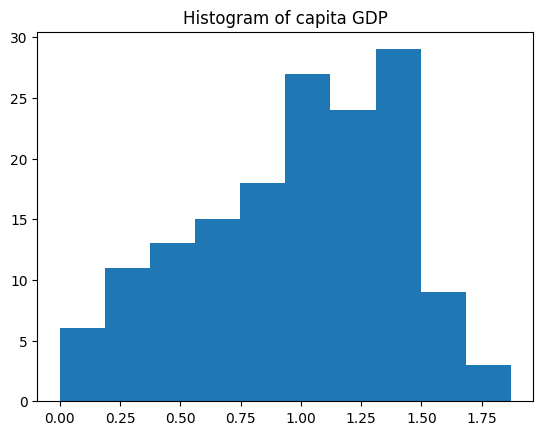

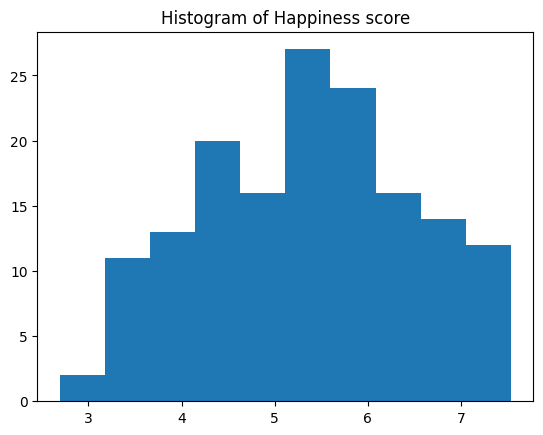

In [3]:
# Pas 2
# see how the data looks (plot the histograms associated to input data - GDP feature - and output data - happiness)

def plotDataHistogram(x, variableName):
    plt.hist(x, 10)
    plt.title('Histogram of ' + variableName)
    plt.show()

plotDataHistogram(inputs, 'capita GDP')
plotDataHistogram(outputs, 'Happiness score')




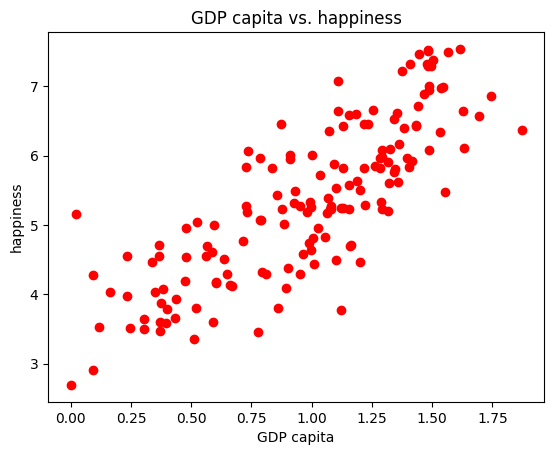

In [4]:
# Pas 3
# check the liniarity (to check that a linear relationship exists between the dependent variable (y = happiness) and the independent variable (x = capita).)

def checkLiniarity(inputs_param, outputs_param):
    plt.plot(inputs_param, outputs_param, 'ro')
    plt.xlabel('GDP capita')
    plt.ylabel('happiness')
    plt.title('GDP capita vs. happiness')
    plt.show()


checkLiniarity(inputs, outputs)


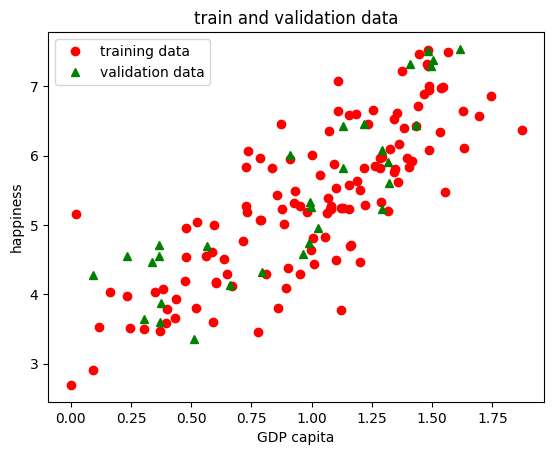

In [5]:
# II
# Pas 4
# Split the Data Into Training and Test Subsets
# In this step we will split our dataset into training and testing subsets (in proportion 80/20%).

# Training data set is used for learning the linear model. Testing dataset is used for validating of the model. All data from testing dataset will be new to model and we may check how accurate are model predictions.

def splitTrainingTest(inputs_param, outputs_param):

    np.random.seed(5)
    indexes = [i for i in range(len(inputs_param))]
    trainSample = np.random.choice(indexes, int(0.8 * len(inputs_param)), replace = False)
    validationSample = [i for i in indexes  if not i in trainSample]

    trainInputs = [inputs_param[i] for i in trainSample]
    trainOutputs = [outputs_param[i] for i in trainSample]

    validationInputs = [inputs_param[i] for i in validationSample]
    validationOutputs = [outputs_param[i] for i in validationSample]

    return trainInputs, trainOutputs, validationInputs, validationOutputs


def plotTrainParams(trainInputs, trainOutputs, validationInputs, validationOutputs):

    plt.plot(trainInputs, trainOutputs, 'ro', label = 'training data')   #train data are plotted by red and circle sign
    plt.plot(validationInputs, validationOutputs, 'g^', label = 'validation data')     #test data are plotted by green and a triangle sign
    plt.title('train and validation data')
    plt.xlabel('GDP capita')
    plt.ylabel('happiness')
    plt.legend()
    plt.show()

trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
plotTrainParams(trainInputs, trainOutputs, validationInputs, validationOutputs)


In [6]:
# III
# Pas 5
# learning step: init and train a linear regression model y = f(x) = w0 + w1 * x
# Prediction step: used the trained model to estimate the output for a new input

# using sklearn
# training data preparation (the sklearn linear model requires as input training data as noSamples x noFeatures array; in the current case, the input must be a matrix of len(trainInputs) lineas and one columns (a single feature is used in this problem))

def trainWithTool(trainInputs_param):
    xx = [[el] for el in trainInputs_param]
    regressor = linear_model.LinearRegression()
    regressor.fit(xx, trainOutputs)
    w0, w1 = regressor.intercept_, regressor.coef_[0]
    return regressor, w0, w1

def printToolRegression(w0, w1):
    print('the learnt model: f(x) = ', w0, ' + ', w1, ' * x')


trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
regressor, w0, w1 = trainWithTool(trainInputs)
printToolRegression(w0, w1)


the learnt model: f(x) =  3.2007686226678995  +  2.1503460961741077  * x


In [7]:
# using developed code
from myRegression import MyLinearUnivariateRegression

def trainWithDevelopedCode(trainInputs_param, trainOutputs_param):
    regressor = MyLinearUnivariateRegression()
    regressor.fit(trainInputs_param, trainOutputs_param)
    w0, w1 = regressor.intercept_, regressor.coef_
    return regressor, w0, w1

def printDevelopedRegression(w0, w1):
    print('the learnt model: f(x) = ', w0, ' + ', w1, ' * x')


trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
regressor, w0, w1 = trainWithDevelopedCode(trainInputs, trainOutputs)
printDevelopedRegression(w0, w1)



the learnt model: f(x) =  3.2007686226678964  +  2.150346096174109  * x


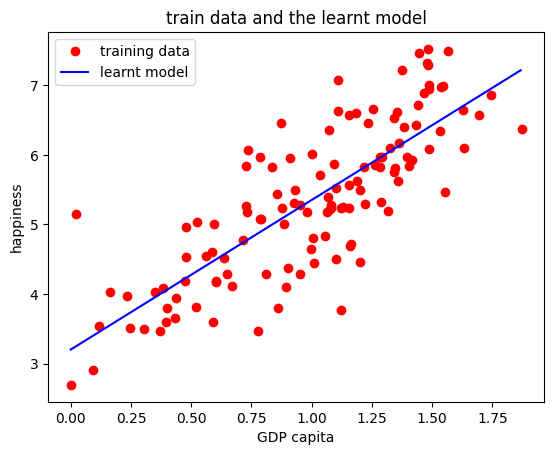

In [8]:
# IV
# Pas 6
# plot the learnt model
# prepare some synthetic data (inputs are random, while the outputs are computed by the learnt model)

def plodLearntModel(trainInputs_param, trainOutputs_param):
    #w0, w1 = trainWithDevelopedCode(trainInputs, trainOutputs)
    regressor, w0, w1 = trainWithTool(trainInputs)
    noOfPoints = 1000
    xref = []
    val = min(trainInputs_param)
    step = (max(trainInputs_param) - min(trainInputs_param)) / noOfPoints
    for i in range(1, noOfPoints):
        xref.append(val)
        val += step
    yref = [w0 + w1 * el for el in xref]

    plt.plot(trainInputs_param, trainOutputs_param, 'ro', label = 'training data')
    plt.plot(xref, yref, 'b-', label = 'learnt model')
    plt.title('train data and the learnt model')
    plt.xlabel('GDP capita')
    plt.ylabel('happiness')
    plt.legend()
    plt.show()

trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
plodLearntModel(trainInputs, trainOutputs)


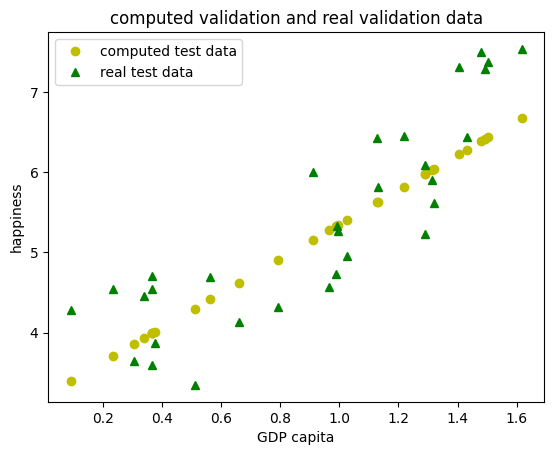

In [9]:
# Pas 7
# use the trained model to predict new inputs

# makes predictions for test data (manual)
# computedTestOutputs = [w0 + w1 * el for el in testInputs]

def predictData(trainInputs_param, trainOutputs_param, validationInputs_param, validationOutputs_param):
    # makes predictions for test data (by tool)
    regressor, w0, w1 = trainWithTool(trainInputs_param)
    computedValidationOutputs = regressor.predict([[x] for x in validationInputs_param])
    return computedValidationOutputs

def plotComputedValidationOutputs(validationInputs_param, validationOutputs_param, computedValidationOutputs_param):
    # plot the computed outputs (see how far they are from the real outputs)
    plt.plot(validationInputs_param, computedValidationOutputs_param, 'yo', label = 'computed test data')  #computed test data are plotted yellow red and circle sign
    plt.plot(validationInputs_param, validationOutputs_param, 'g^', label = 'real test data')  #real test data are plotted by green triangles
    plt.title('computed validation and real validation data')
    plt.xlabel('GDP capita')
    plt.ylabel('happiness')
    plt.legend()
    plt.show()


trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
plotComputedValidationOutputs(validationInputs, validationOutputs, computedValidationOutputs)


In [10]:
# V
# Pas 8
# compute the differences between the predictions and real outputs
# "manual" computation

def getError(computedValidationOutputs_param, validationOutputs_param):
    error = 0.0
    for t1, t2 in zip(computedValidationOutputs_param, validationOutputs_param):
        error += (t1 - t2) ** 2
    error = error / len(validationOutputs_param)
    print('prediction error (manual): ', error)

    # by using sklearn
    from sklearn.metrics import mean_squared_error

    error = mean_squared_error(validationOutputs_param, computedValidationOutputs_param)
    print('prediction error (tool):  ', error)


trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
getError(computedValidationOutputs, validationOutputs)


prediction error (manual):  0.4142120438505252
prediction error (tool):   0.41421204385052524


Pas 1

in:   [1.616463184, 1.482383013, 1.48063302, 1.564979553, 1.443571925]
out:  [7.537000179, 7.521999836, 7.504000187, 7.493999958, 7.468999863]


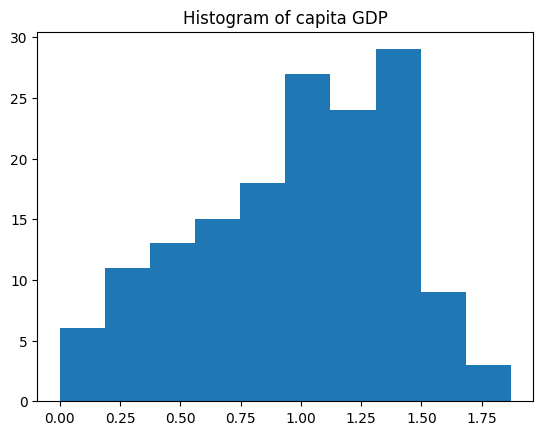

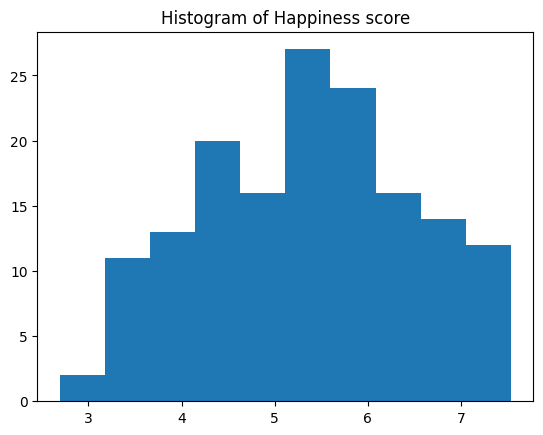

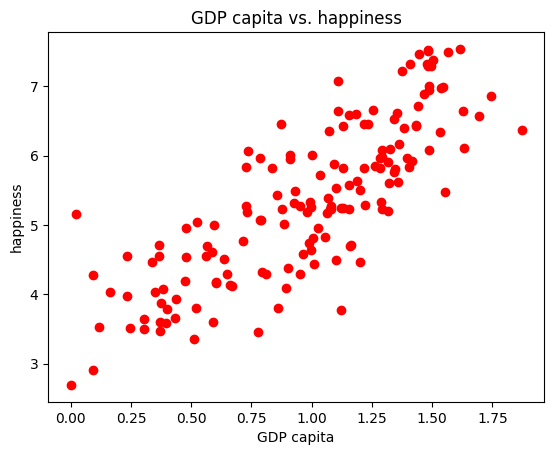


Pas 2



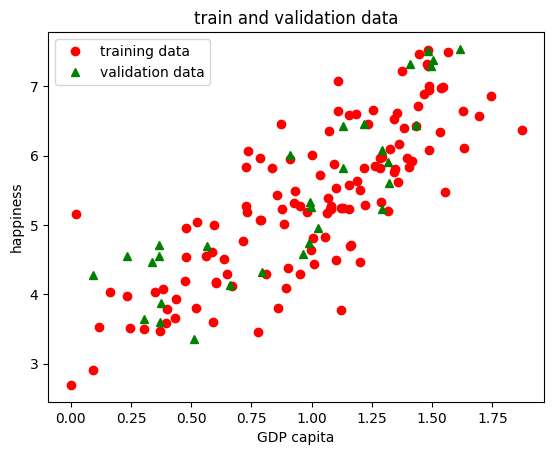


Pas 3

the learnt model: f(x) =  3.2007686226678995  +  2.1503460961741077  * x
the learnt model: f(x) =  3.2007686226678964  +  2.150346096174109  * x

Pas 4



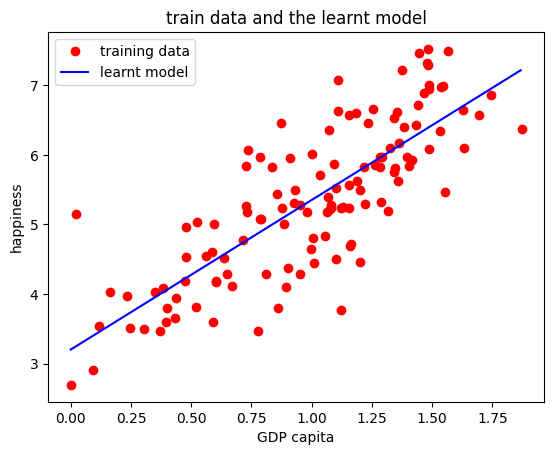

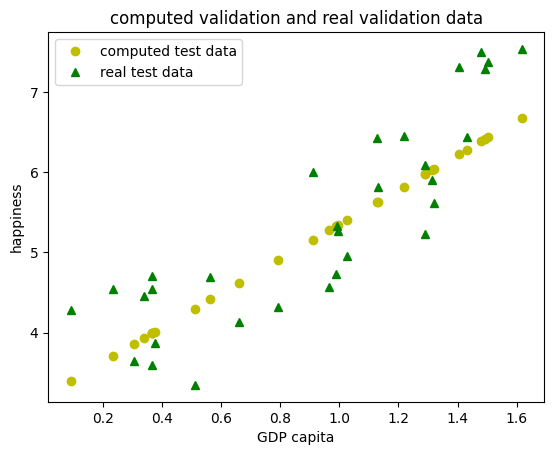


Pas 5

prediction error (manual):  0.4142120438505252
prediction error (tool):   0.41421204385052524


In [11]:
# DATE V2 -> GDP

print("Pas 1")
print()

crtDir =  os.getcwd()
filePath = os.path.join(crtDir, 'data', 'v2_world-happiness-report-2017.csv')

inputs, outputs = loadData(filePath, 'Economy..GDP.per.Capita.', 'Happiness.Score')
print('in:  ', inputs[:5])
print('out: ', outputs[:5])



plotDataHistogram(inputs, 'capita GDP')
plotDataHistogram(outputs, 'Happiness score')



checkLiniarity(inputs, outputs)


print()
print("Pas 2")
print()

trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
plotTrainParams(trainInputs, trainOutputs, validationInputs, validationOutputs)


print()
print("Pas 3")
print()

regressor, w0, w1 = trainWithTool(trainInputs)
printToolRegression(w0, w1)

regressor, w0, w1 = trainWithDevelopedCode(trainInputs, trainOutputs)
printDevelopedRegression(w0, w1)


print()
print("Pas 4")
print()

plodLearntModel(trainInputs, trainOutputs)
computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
plotComputedValidationOutputs(validationInputs, validationOutputs, computedValidationOutputs)


print()
print("Pas 5")
print()


computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
getError(computedValidationOutputs, validationOutputs)


Pas 1

in:   [1.616463184, 1.482383013, 1.48063302, 1.564979553, 1.443571925]
out:  [7.537000179, 7.521999836, 7.504000187, 7.493999958, 7.468999863]


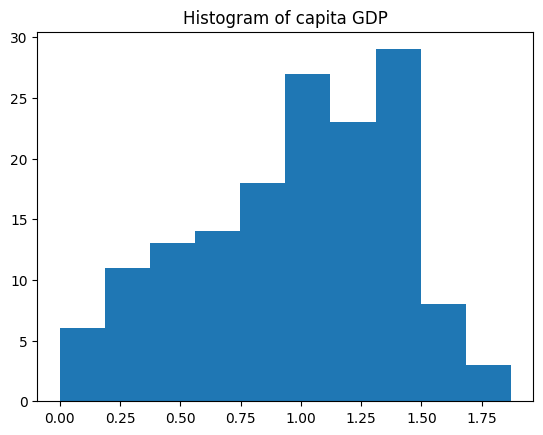

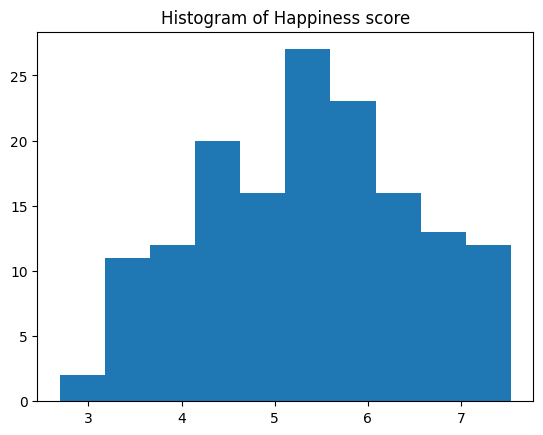

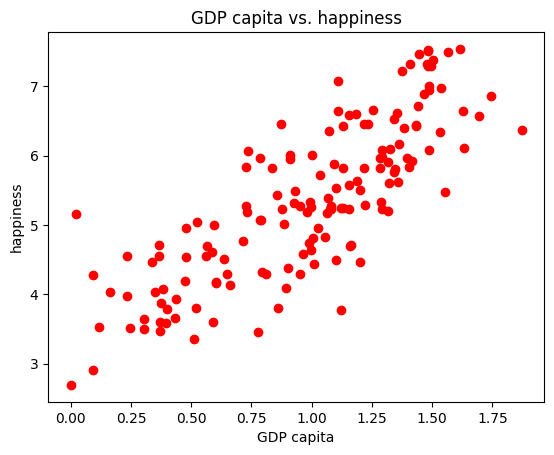


Pas 2



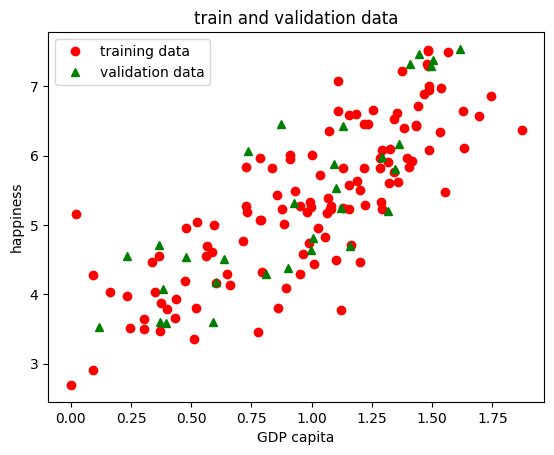


Pas 3

the learnt model: f(x) =  3.2590669479039853  +  2.109207536959527  * x
the learnt model: f(x) =  3.259066947903982  +  2.10920753695953  * x

Pas 4



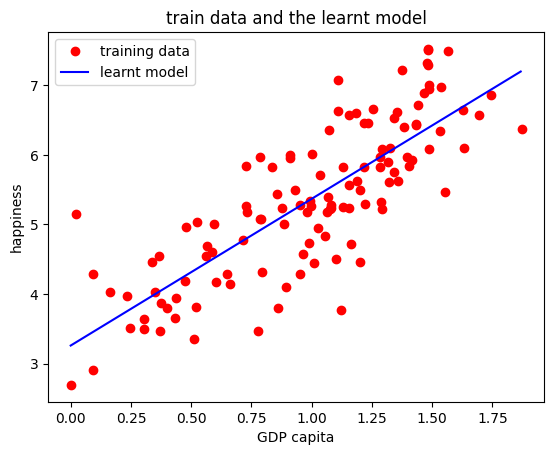

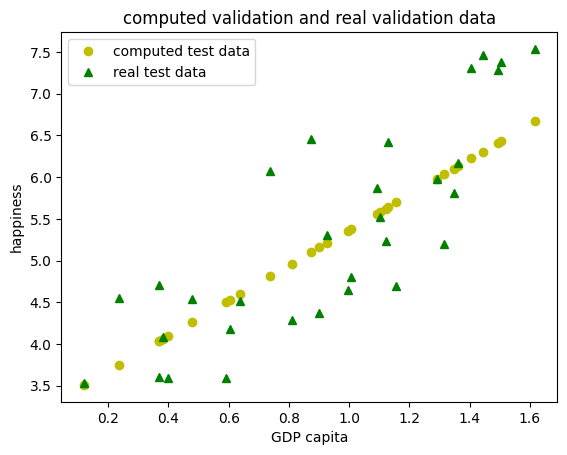


Pas 5

prediction error (manual):  0.5011920687289553
prediction error (tool):   0.5011920687289554


In [12]:
# DATE V3 -> GDP

print("Pas 1")
print()

crtDir =  os.getcwd()
filePath = os.path.join(crtDir, 'data', 'v3_world-happiness-report-2017.csv')

inputs, outputs = loadData(filePath, 'Economy..GDP.per.Capita.', 'Happiness.Score')
print('in:  ', inputs[:5])
print('out: ', outputs[:5])



plotDataHistogram(inputs, 'capita GDP')
plotDataHistogram(outputs, 'Happiness score')



checkLiniarity(inputs, outputs)


print()
print("Pas 2")
print()

trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
plotTrainParams(trainInputs, trainOutputs, validationInputs, validationOutputs)


print()
print("Pas 3")
print()

regressor, w0, w1 = trainWithTool(trainInputs)
printToolRegression(w0, w1)

regressor, w0, w1 = trainWithDevelopedCode(trainInputs, trainOutputs)
printDevelopedRegression(w0, w1)


print()
print("Pas 4")
print()

plodLearntModel(trainInputs, trainOutputs)

computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
plotComputedValidationOutputs(validationInputs, validationOutputs, computedValidationOutputs)


print()
print("Pas 5")
print()


computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
getError(computedValidationOutputs, validationOutputs)


Pas 1

in:   [1.510041952, 1.510041952, 1.510041952, 1.510041952, 1.510041952]
out:  [7.537000179, 7.521999836, 7.504000187, 7.493999958, 7.468999863]


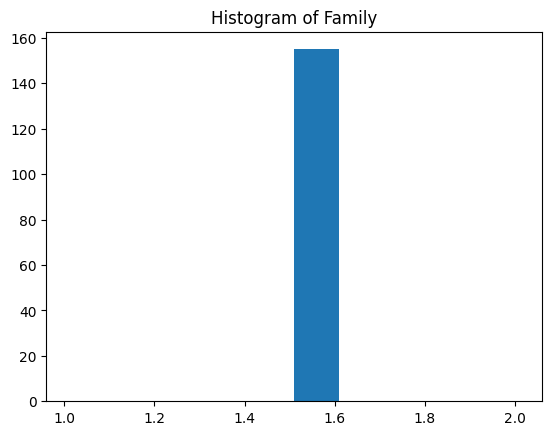

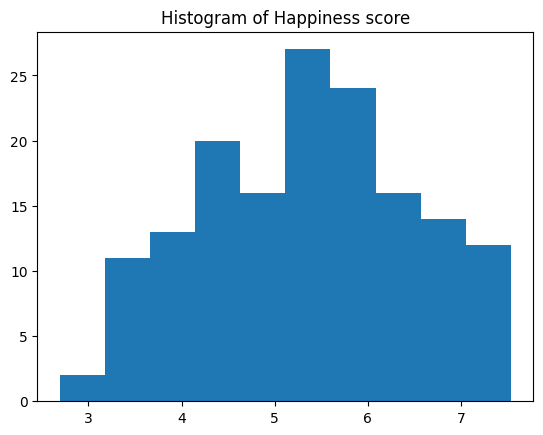

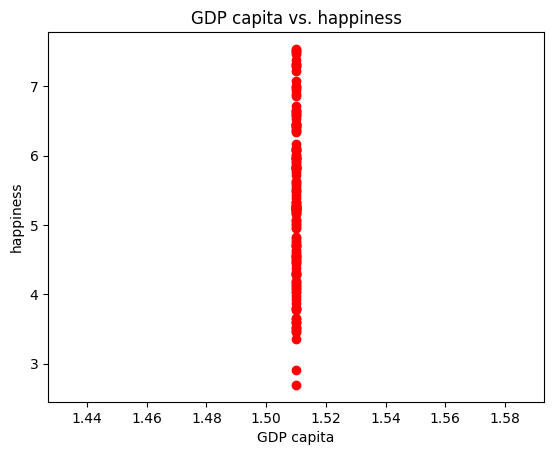


Pas 2



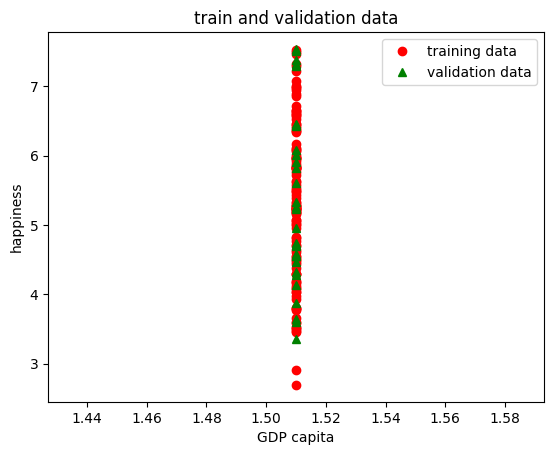


Pas 3

the learnt model: f(x) =  0.4719180650554877  +  3.2328954364819484  * x
the learnt model: f(x) =  5.3537258005725805  +  0.0  * x

Pas 4



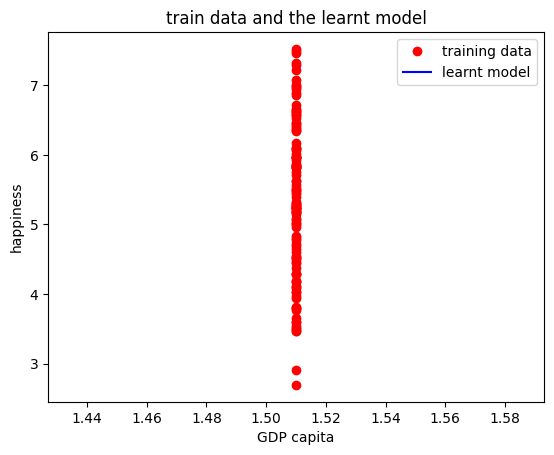

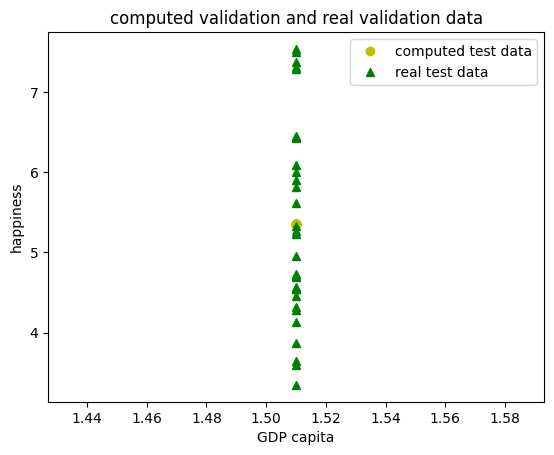


Pas 5

prediction error (manual):  1.488969965516146
prediction error (tool):   1.488969965516146


In [13]:
# DATE V1 -> Family

print("Pas 1")
print()

crtDir =  os.getcwd()
filePath = os.path.join(crtDir, 'data', 'v1_world-happiness-report-2017.csv')

inputs, outputs = loadData(filePath, 'Family', 'Happiness.Score')
print('in:  ', inputs[:5])
print('out: ', outputs[:5])



plotDataHistogram(inputs, 'Family')
plotDataHistogram(outputs, 'Happiness score')



checkLiniarity(inputs, outputs)


print()
print("Pas 2")
print()

trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
plotTrainParams(trainInputs, trainOutputs, validationInputs, validationOutputs)


print()
print("Pas 3")
print()

regressor, w0, w1 = trainWithTool(trainInputs)
printToolRegression(w0, w1)

regressor, w0, w1 = trainWithDevelopedCode(trainInputs, trainOutputs)
printDevelopedRegression(w0, w1)


print()
print("Pas 4")
print()

plodLearntModel(trainInputs, trainOutputs)

computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
plotComputedValidationOutputs(validationInputs, validationOutputs, computedValidationOutputs)


print()
print("Pas 5")
print()


computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
getError(computedValidationOutputs, validationOutputs)


Pas 1

in:   [1.53352356, 1.551121593, 1.610574007, 1.516911745, 1.540246725]
out:  [7.537000179, 7.521999836, 7.504000187, 7.493999958, 7.468999863]


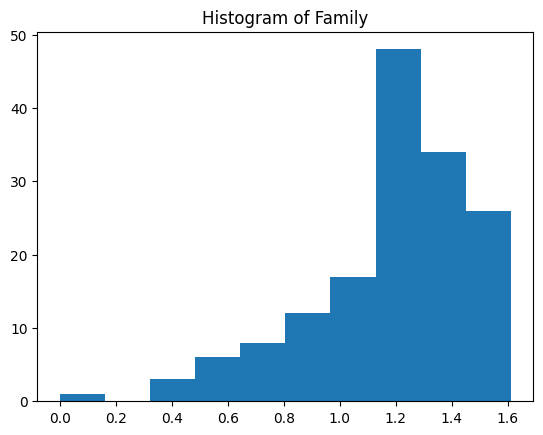

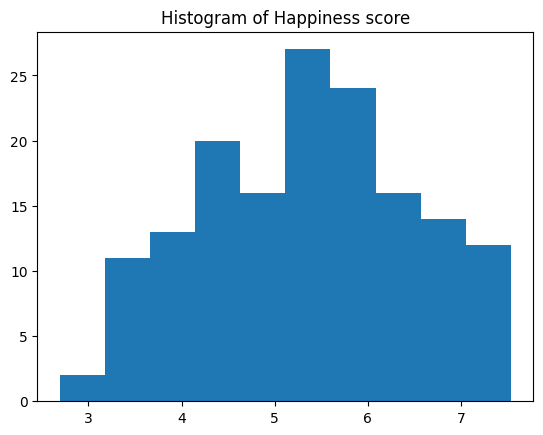

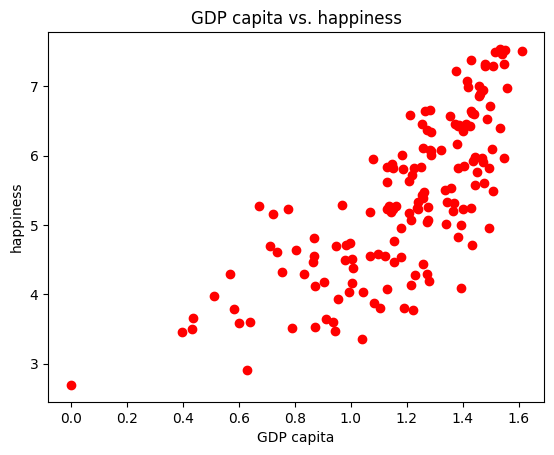


Pas 2



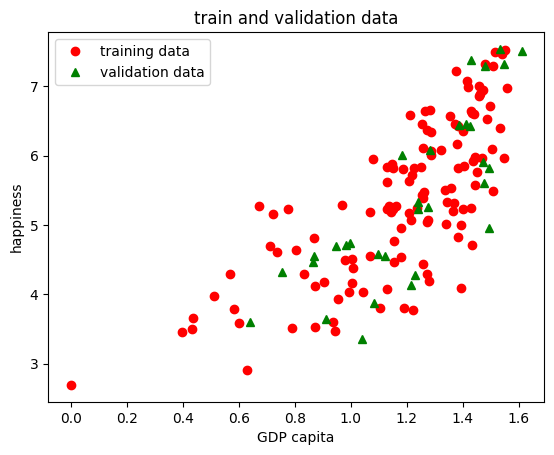


Pas 3

the learnt model: f(x) =  2.039013930022846  +  2.804913617557077  * x
the learnt model: f(x) =  2.0390139300228274  +  2.804913617557092  * x

Pas 4



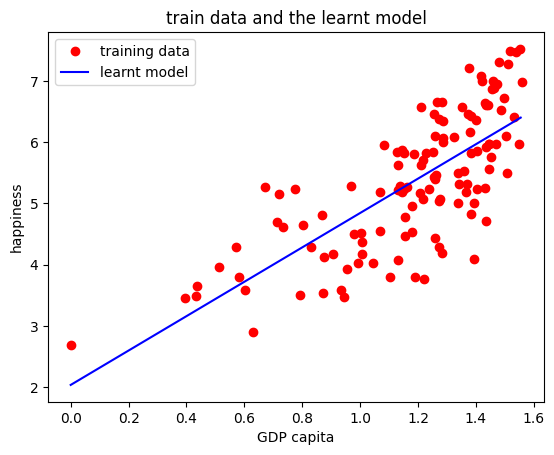

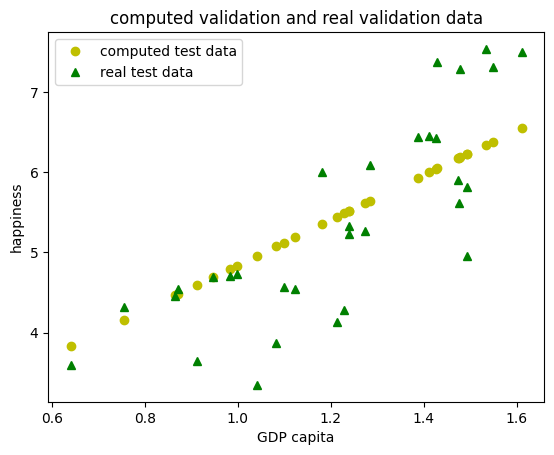


Pas 5

prediction error (manual):  0.6051231125473607
prediction error (tool):   0.6051231125473606


In [14]:
# DATE V2 -> Family

print("Pas 1")
print()

crtDir =  os.getcwd()
filePath = os.path.join(crtDir, 'data', 'v2_world-happiness-report-2017.csv')

inputs, outputs = loadData(filePath, 'Family', 'Happiness.Score')
print('in:  ', inputs[:5])
print('out: ', outputs[:5])



plotDataHistogram(inputs, 'Family')
plotDataHistogram(outputs, 'Happiness score')



checkLiniarity(inputs, outputs)


print()
print("Pas 2")
print()

trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
plotTrainParams(trainInputs, trainOutputs, validationInputs, validationOutputs)


print()
print("Pas 3")
print()

regressor, w0, w1 = trainWithTool(trainInputs)
printToolRegression(w0, w1)

regressor, w0, w1 = trainWithDevelopedCode(trainInputs, trainOutputs)
printDevelopedRegression(w0, w1)


print()
print("Pas 4")
print()

plodLearntModel(trainInputs, trainOutputs)

computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
plotComputedValidationOutputs(validationInputs, validationOutputs, computedValidationOutputs)


print()
print("Pas 5")
print()


computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
getError(computedValidationOutputs, validationOutputs)


Pas 1

in:   [1.53352356, 1.551121593, 1.610574007, 1.516911745, 1.540246725]
out:  [7.537000179, 7.521999836, 7.504000187, 7.493999958, 7.468999863]


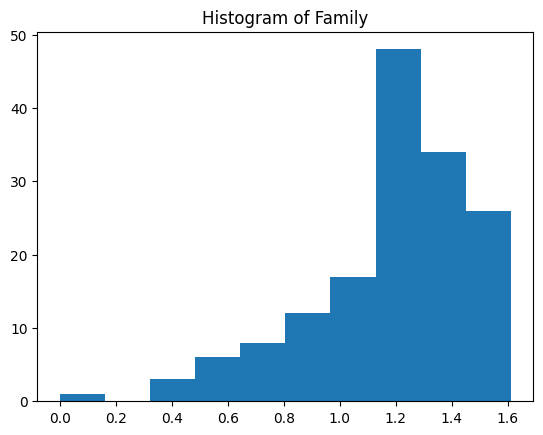

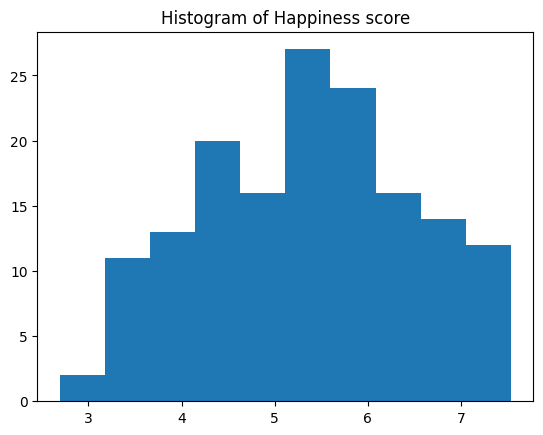

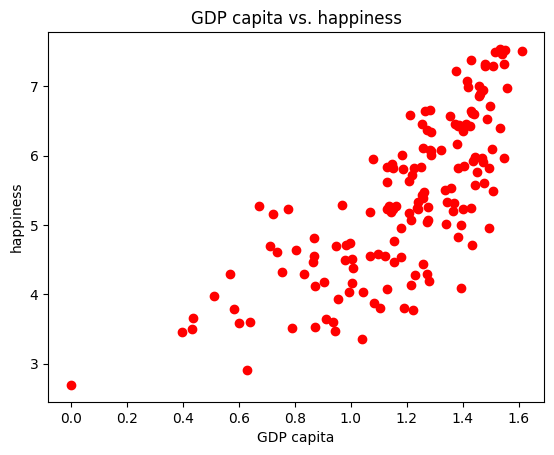


Pas 2



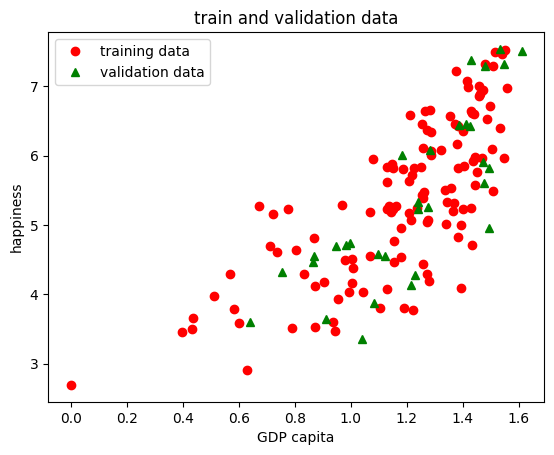


Pas 3

the learnt model: f(x) =  2.039013930022846  +  2.804913617557077  * x
the learnt model: f(x) =  2.0390139300228274  +  2.804913617557092  * x

Pas 4



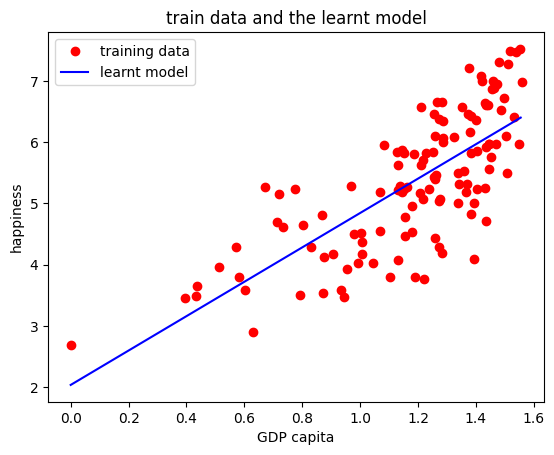

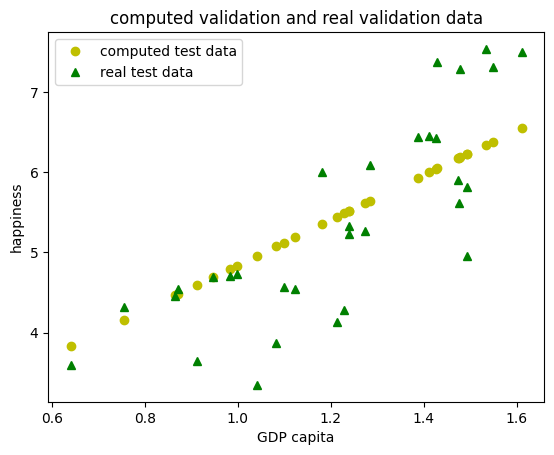


Pas 5

prediction error (manual):  0.6051231125473607
prediction error (tool):   0.6051231125473606


In [15]:
# DATE V3 -> Family

print("Pas 1")
print()

crtDir =  os.getcwd()
filePath = os.path.join(crtDir, 'data', 'v3_world-happiness-report-2017.csv')

inputs, outputs = loadData(filePath, 'Family', 'Happiness.Score')
print('in:  ', inputs[:5])
print('out: ', outputs[:5])



plotDataHistogram(inputs, 'Family')
plotDataHistogram(outputs, 'Happiness score')



checkLiniarity(inputs, outputs)


print()
print("Pas 2")
print()

trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest(inputs, outputs)
plotTrainParams(trainInputs, trainOutputs, validationInputs, validationOutputs)


print()
print("Pas 3")
print()

regressor, w0, w1 = trainWithTool(trainInputs)
printToolRegression(w0, w1)

regressor, w0, w1 = trainWithDevelopedCode(trainInputs, trainOutputs)
printDevelopedRegression(w0, w1)


print()
print("Pas 4")
print()

plodLearntModel(trainInputs, trainOutputs)

computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
plotComputedValidationOutputs(validationInputs, validationOutputs, computedValidationOutputs)


print()
print("Pas 5")
print()


computedValidationOutputs = predictData(trainInputs, trainOutputs, validationInputs, validationOutputs)
getError(computedValidationOutputs, validationOutputs)
